In [25]:
from numpy import random
import warnings
warnings.filterwarnings('ignore')
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
import seaborn as sns

In [2]:
dataset = pd.read_csv('dataset.csv')
dataset

,timestamp,alpha,beta,delta,theta,gamma,arousal,valence,total_power,alpha_beta_ratio,theta_alpha_ratio,high_freq_ratio,frontal_alpha,parietal_alpha,temporal_beta,occipital_alpha,relaxation_index,attention_index,meditation_index,emotion
0,0,8.247225,9.423885,3.317986,6.848153,19.435433,0.607953,0.156294,47.620646,1.012549,0.700308,1.676683,8.022614,9.216866,7.198457,8.113871,1.001758,1.430617,0.529654,angry
1,1,15.740955,8.811577,4.340034,3.508749,19.090487,0.448033,0.571099,50.641114,1.757765,0.254667,2.287797,13.700040,11.093503,7.370500,13.830256,1.489487,2.276984,0.577979,excited
2,2,13.431451,18.928064,3.822576,8.073970,7.039027,0.909241,0.244801,48.817353,0.722878,0.595979,0.614908,11.195104,9.512846,19.830748,12.783523,0.575854,2.438770,1.448442,angry
3,3,10.858108,7.683628,1.487260,6.093926,23.090646,0.535689,0.304990,51.623056,1.255244,0.584000,3.256180,11.507738,12.460602,9.152181,9.166604,1.370618,1.419380,0.597654,happy
4,4,6.438594,9.425397,1.603746,3.685656,15.415629,0.914278,0.276102,38.198771,0.703721,0.580300,3.046505,6.530458,6.660719,10.081406,7.060187,0.716657,2.328471,0.388687,angry
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,1995,11.860894,11.831078,3.647643,4.454917,23.422682,0.772868,0.418791,51.117699,1.014926,0.410851,2.613697,9.686101,11.308915,9.662922,11.633668,0.799273,2.541720,0.534304,happy
1996,1996,14.590192,9.062127,3.189840,4.053397,22.490682,0.577447,0.551513,50.889004,1.500779,0.285532,3.107628,16.469461,17.365688,9.887158,14.830137,1.647180,2.242087,0.773464,happy
1997,1997,5.642033,10.332078,3.900781,5.156196,25.146766,0.983730,0.036343,51.323617,0.544353,1.033053,2.505590,5.137535,5.667318,13.467848,6.758575,0.439032,2.087534,0.233148,angry
1998,1998,5.611278,12.889679,3.021238,7.731975,12.835816,1.026983,-0.139114,38.989049,0.447736,1.367540,1.152700,6.268343,4.987885,14.072374,5.995690,0.507887,1.918651,0.419952,angry


([0, 1, 2, 3],
 [Text(0, 0, 'angry'),
  Text(1, 0, 'excited'),
  Text(2, 0, 'happy'),
  Text(3, 0, 'sad')])

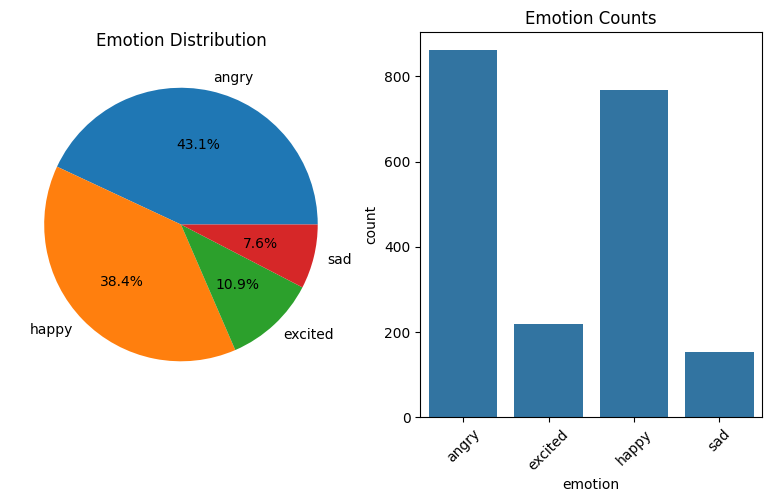

In [27]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
emotion_counts = dataset['emotion'].value_counts()
plt.pie(emotion_counts.values, labels=emotion_counts.index, autopct='%1.1f%%')
plt.title('Emotion Distribution')

plt.subplot(1, 3, 2)
sns.countplot(data=dataset, x='emotion')
plt.title('Emotion Counts')
plt.xticks(rotation=45)

EEG WAVE PATTERN VISUALIZATION


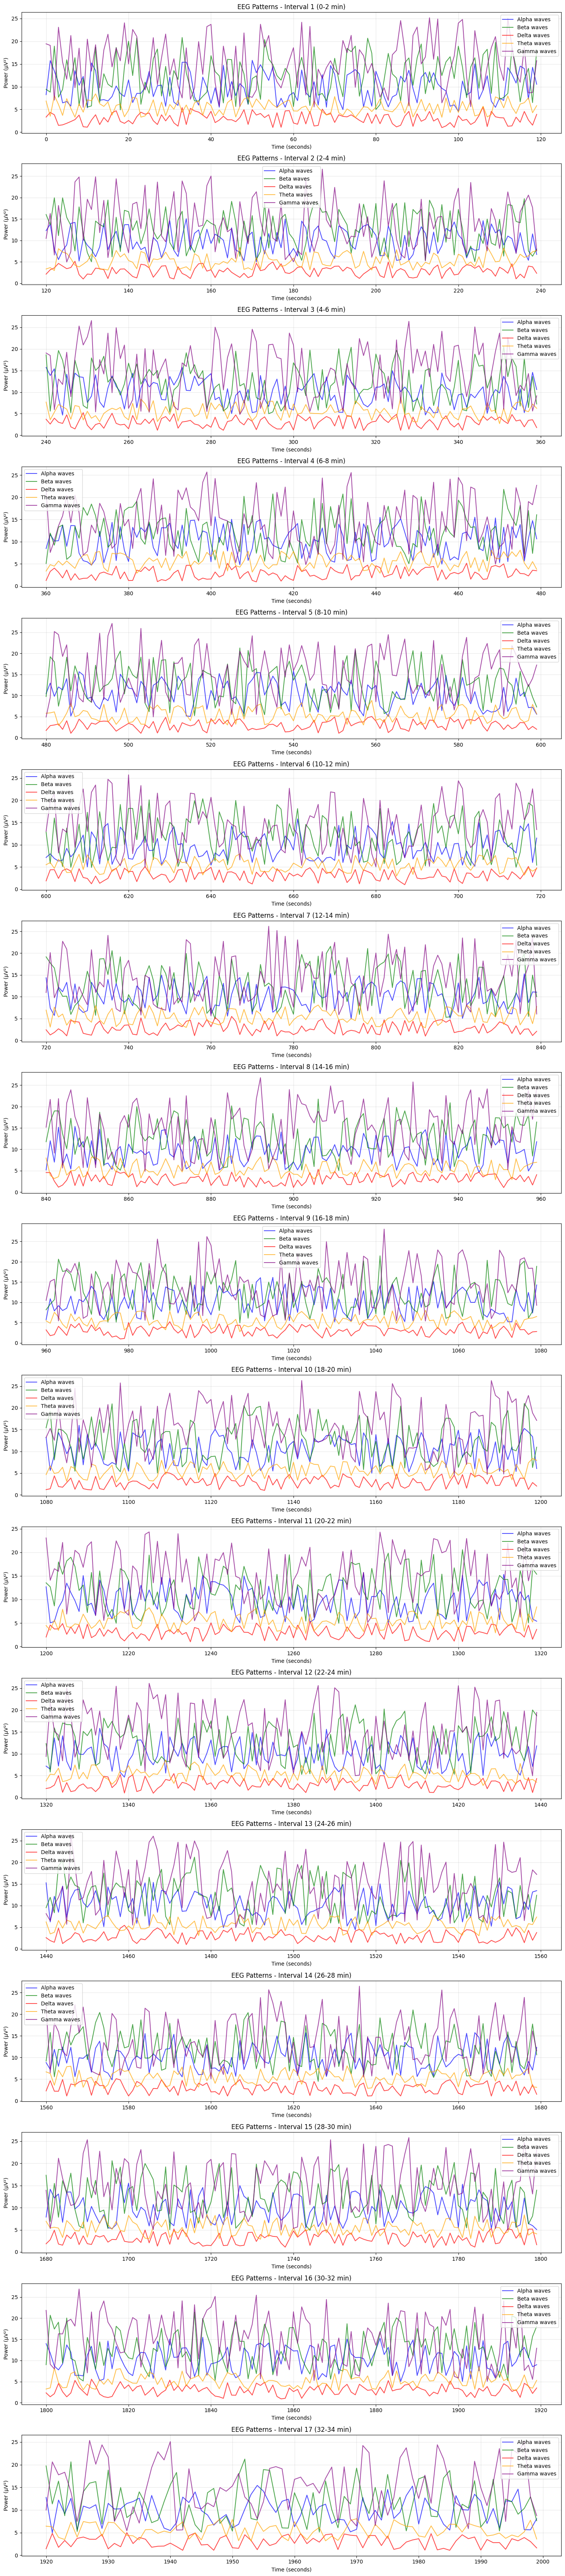

In [28]:
print("EEG WAVE PATTERN VISUALIZATION")
print("=" * 50)

def plot_eeg_intervals_auto(df, interval_minutes=3):
    """
    Automatically split and plot EEG data into intervals of given minutes
    """
    interval_seconds = interval_minutes * 60
    max_time = df['timestamp'].max()
    num_intervals = int(max_time // interval_seconds) + 1  # Ensures full coverage

    # Create subplots
    fig, axes = plt.subplots(num_intervals, 1, figsize=(15, 4 * num_intervals))
    
    # Ensure axes is always a list (even if there's only one subplot)
    if num_intervals == 1:
        axes = [axes]
    else:
        axes = axes.flatten().tolist()

    colors = ['blue', 'green', 'red', 'orange', 'purple']
    bands = ['alpha', 'beta', 'delta', 'theta', 'gamma']

    for i in range(num_intervals):
        start_time = i * interval_seconds
        end_time = (i + 1) * interval_seconds

        interval_data = df[(df['timestamp'] >= start_time) & (df['timestamp'] < end_time)]

        if not interval_data.empty:
            for j, band in enumerate(bands):
                axes[i].plot(interval_data['timestamp'], interval_data[band],
                             color=colors[j], label=f'{band.capitalize()} waves', alpha=0.7)

            axes[i].set_title(f'EEG Patterns - Interval {i+1} ({start_time//60}-{end_time//60} min)')
            axes[i].set_xlabel('Time (seconds)')
            axes[i].set_ylabel('Power (μV²)')
            axes[i].legend()
            axes[i].grid(True, alpha=0.3)
        else:
            axes[i].set_visible(False)

    plt.tight_layout()
    plt.show()

plot_eeg_intervals_auto(dataset, interval_minutes=2)

In [16]:
x_train=dataset.drop(['emotion','timestamp'],axis=1)
y_train=dataset[['emotion']]
le = LabelEncoder()
y_encoded = le.fit_transform(y_train)

X_train, X_test, Y_train, Y_test = train_test_split(x_train,y_encoded, test_size=0.20, random_state=42)


In [17]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

ytest = to_categorical(Y_test)
ytrain = to_categorical(Y_train)


In [21]:
Xtrain = np.array(X_train)
Xtrain = np.reshape(Xtrain, (Xtrain.shape[0], Xtrain.shape[1], 1))
Xtest = np.array(X_test)
Xtest = np.reshape(Xtest, (Xtest.shape[0], Xtest.shape[1], 1))


In [22]:
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout, BatchNormalization
from keras.regularizers import l2
from keras.callbacks import EarlyStopping, LearningRateScheduler
from keras.callbacks import ModelCheckpoint, EarlyStopping, LearningRateScheduler
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
# Define early stopping and learning rate scheduler callbacks
initial_learning_rate = 0.001
def lr_schedule(epoch):
    return initial_learning_rate * (0.1 ** (epoch // 10))

early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
lr_scheduler = LearningRateScheduler(lr_schedule)

# Define the rest of your callbacks
my_callbacks = [
    ModelCheckpoint(filepath='cnnlstm.h5', verbose=1, save_best_only=True, monitor='val_accuracy', mode='max'),
    early_stopping,
    lr_scheduler
]
model = Sequential()

# Add Convolutional and MaxPooling Layers with L2 Regularization
model.add(Conv1D(64, 3, padding="same", input_shape=(Xtrain.shape[1], 1), activation='relu', kernel_regularizer=l2(0.01)))
model.add(Conv1D(64, 3, padding="same", activation='relu', kernel_regularizer=l2(0.01)))
model.add(MaxPooling1D(pool_size=2))
model.add(Conv1D(128, 3, padding="same", activation='relu', kernel_regularizer=l2(0.001)))
model.add(Conv1D(128, 3, padding="same", activation='relu', kernel_regularizer=l2(0.001)))
model.add(MaxPooling1D(pool_size=2))

# Add Batch Normalization
model.add(BatchNormalization())

# Add LSTM layer with L2 Regularization
model.add(LSTM(units=100, return_sequences=False, dropout=0.1, kernel_regularizer=l2(0.01)))
model.add(Dropout(0.5))  # Add dropout to reduce overfitting

# Add Dense layer with L2 Regularization
model.add(Dense(units=4, activation='softmax', kernel_regularizer=l2(0.01)))  # 4 classes with softmax activation

# Compile the model with a custom learning rate schedule
opt = Adam(learning_rate=initial_learning_rate)
model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

model.summary()


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d_4 (Conv1D)           (None, 18, 64)            256       
                                                                 
 conv1d_5 (Conv1D)           (None, 18, 64)            12352     
                                                                 
 max_pooling1d_2 (MaxPooling  (None, 9, 64)            0         
 1D)                                                             
                                                                 
 conv1d_6 (Conv1D)           (None, 9, 128)            24704     
                                                                 
 conv1d_7 (Conv1D)           (None, 9, 128)            49280     
                                                                 
 max_pooling1d_3 (MaxPooling  (None, 4, 128)           0         
 1D)                                                  

In [23]:

history = model.fit(Xtrain, ytrain, epochs=10, batch_size=64, validation_data=(Xtest, ytest), callbacks=my_callbacks)


Epoch 1/10
25/25 [==============================] - ETA: 0s - loss: 3.2997 - accuracy: 0.6231
Epoch 1: val_accuracy improved from -inf to 0.35750, saving model to cnnlstm.h5
25/25 [==============================] - 8s 110ms/step - loss: 3.2997 - accuracy: 0.6231 - val_loss: 3.2705 - val_accuracy: 0.3575 - lr: 0.0010
Epoch 2/10
24/25 [===========================>..] - ETA: 0s - loss: 2.2681 - accuracy: 0.7630
Epoch 2: val_accuracy improved from 0.35750 to 0.71500, saving model to cnnlstm.h5
25/25 [==============================] - 2s 65ms/step - loss: 2.2561 - accuracy: 0.7644 - val_loss: 2.3250 - val_accuracy: 0.7150 - lr: 0.0010
Epoch 3/10
25/25 [==============================] - ETA: 0s - loss: 1.6635 - accuracy: 0.8119
Epoch 3: val_accuracy improved from 0.71500 to 0.82500, saving model to cnnlstm.h5
25/25 [==============================] - 1s 57ms/step - loss: 1.6635 - accuracy: 0.8119 - val_loss: 1.7353 - val_accuracy: 0.8250 - lr: 0.0010
Epoch 4/10
25/25 [========================

In [29]:
history1 = model.fit(Xtrain, ytrain, epochs=30, batch_size=64, validation_data=(Xtest, ytest), callbacks=my_callbacks)

Epoch 1/30
24/25 [===========================>..] - ETA: 0s - loss: 0.7736 - accuracy: 0.8724
Epoch 1: val_accuracy did not improve from 0.88500
25/25 [==============================] - 1s 55ms/step - loss: 0.7700 - accuracy: 0.8744 - val_loss: 0.8615 - val_accuracy: 0.8250 - lr: 0.0010
Epoch 2/30
24/25 [===========================>..] - ETA: 0s - loss: 0.7368 - accuracy: 0.8743
Epoch 2: val_accuracy did not improve from 0.88500
25/25 [==============================] - 1s 50ms/step - loss: 0.7324 - accuracy: 0.8763 - val_loss: 0.7810 - val_accuracy: 0.8600 - lr: 0.0010
Epoch 3/30
24/25 [===========================>..] - ETA: 0s - loss: 0.7237 - accuracy: 0.8633
Epoch 3: val_accuracy did not improve from 0.88500
25/25 [==============================] - 1s 50ms/step - loss: 0.7283 - accuracy: 0.8612 - val_loss: 1.5677 - val_accuracy: 0.6525 - lr: 0.0010
Epoch 4/30
25/25 [==============================] - ETA: 0s - loss: 0.6949 - accuracy: 0.8813
Epoch 4: val_accuracy did not improve from

In [30]:
model.save('model.h5')

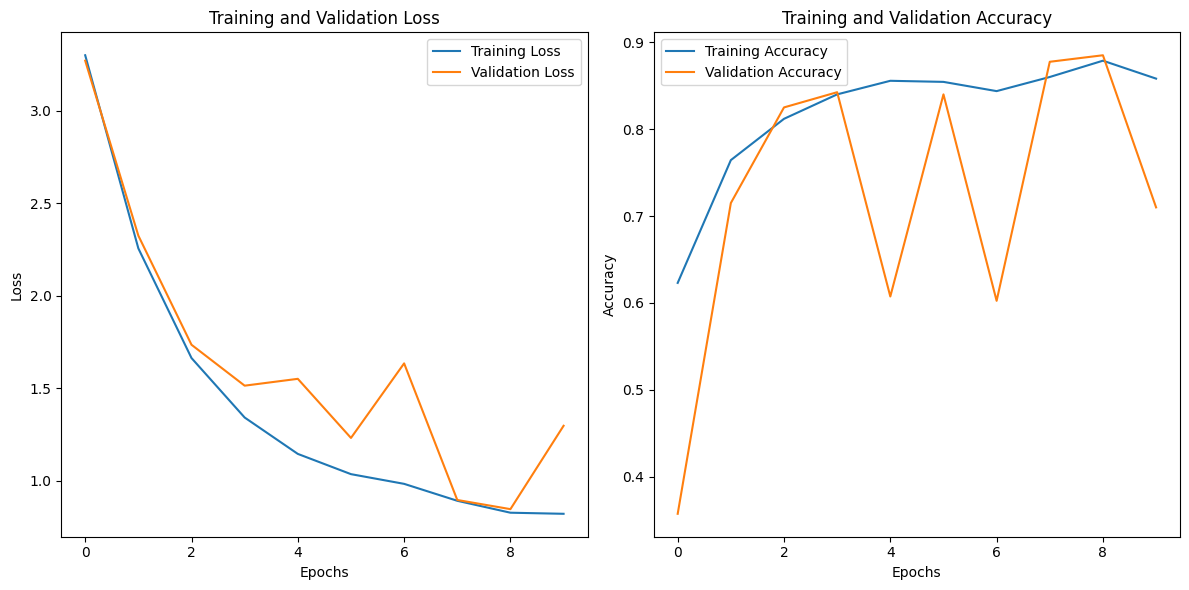

In [31]:
import matplotlib.pyplot as plt

# Extract loss and accuracy data from the history object
history_dict = history.history
loss = history_dict['loss']
val_loss = history_dict['val_loss']
accuracy = history_dict['accuracy']
val_accuracy = history_dict['val_accuracy']

# Plot Training and Validation Loss
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)  # Subplot for loss
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Plot Training and Validation Accuracy
plt.subplot(1, 2, 2)  # Subplot for accuracy
plt.plot(accuracy, label='Training Accuracy')
plt.plot(val_accuracy, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Show the plot
plt.tight_layout()
plt.show()
